# Building a catalog at 1.0 < z < 1.2

This notebook builds a Roman-like catalog of Hα emitters at 1.0 < z < 1.2, with line interlopers, from the base catalog of
the diffsky mock. RomanMock does it in two steps:

1. **`base.make_proposal(z_range, line, thresholds)`**: one pass over the base catalog, before any identification is
   chosen, counts against redshift the single-line galaxies the catalog would hold (which line is single) and the
   *potential interlopers*: single-line galaxies at other redshifts whose line falls where the target line would be for
   a redshift inside the range.
2. **`proposal.make_catalog(confusion, out_dir)`**: the identification of the single-line galaxies (a confusion table,
   or the line mix of the mock, `"empirical"`) and the catalog, written with the same thresholds.

Both steps rescale the oxygen lines of the mock (`rescaling=RESCALING`, set in the first cell) and count
[O III] λ4959 as a line of its own only where the doublet is resolved for the galaxy's size (`doublets="per_galaxy"`);
the README explains how both work.

**The rescaling.** In the raw mock (the line fluxes as diffsky gives them) [O III]/Hβ is nearly the same in every
galaxy, with a spread of 0.01 dex, and [O II] is fainter than Hβ in more than nine galaxies of ten. The rescaling
changes the oxygen lines only:

* [O III] λλ4959, 5007 get a log-normal scatter of 0.19 dex;
* [O II] is brightened by 0.25 dex (1.78 times) and gets a scatter of 0.11 dex;
* one normal deviate per galaxy drives both, so the oxygen lines of a galaxy move together. Every other line stays raw.

[O III]/Hβ then has about the spread of the Galacticus mock of the GRS-PIT (0.19 dex against 0.18), and [O II] is
brighter than Hβ in about eight galaxies of ten, as in Galacticus. Without `rescaling=`, `make_proposal` uses `"galacticus_like"`, an
earlier rescaling that also shifts the medians of Hβ, [O III], [S III] and Paα toward Galacticus.

**The base catalog** holds every galaxy of the mock with a line above 1.0 × 10⁻¹⁸ erg s⁻¹ cm⁻² inside the grism
bandpass (10 000–19 300 Å), with all its line fluxes: 403 M galaxies over 2578 deg². It has to be much deeper than any
threshold of step 1, because the rescaling can brighten a line by up to 8.9 times (a 5σ deviate) and the merged
doublet by another 1.34 times: a galaxy lifted above the threshold from below the base limit would be missing. The
faintest threshold here, S/N 5 for a point source in one hour, is 3.1 × 10⁻¹⁷, 30 times the base limit.

The notebook reads the base catalog six times. Run it on a CPU node, from the package directory:
`sbatch scripts/run_notebook.sh notebooks/01_catalog_z1p0_1p2.ipynb` (about 3 minutes). The catalogs go to
`$PSCRATCH/RomanMocks/examples/`, where notebook 03 makes their random catalogs.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")      # romanmock imports diffsky, which imports JAX; keep it off the GPU

import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from romanmock import BaseCatalog, Catalog, LineFactors, Proposal, plotting
from romanmock.plotting import OUTCOME_COLORS, TEXT_PRIMARY, feature_color, feature_label

plotting.use_style()
BASE = "/global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base"
OUT = Path(os.environ["PSCRATCH"]) / "RomanMocks" / "examples"      # scratch: purged after 8 weeks without access
N_WORKERS = 64 if "SLURM_JOB_ID" in os.environ else None           # a whole CPU node; None: what a login node allows
base = BaseCatalog(BASE)
print(base)

# The rescaling of the oxygen lines (introduction of notebook 01): [O III] gets a scatter of 0.19 dex, and [O II] is
# brightened by 0.25 dex with a scatter of 0.11 dex. One deviate per galaxy; the other lines keep their raw fluxes.
RESCALING = LineFactors(log_offsets={"OII_3727": 0.25}, scatter={"OIII_5007": 0.19, "OIII_4959": 0.19, "OII_3727": 0.11})
print(RESCALING.describe(base.line_set))


<BaseCatalog /global/cfs/cdirs/m4943/Simulations/RomanMocks/sdss_feniks_hizels_261013_10_14_2026/base: 403,068,868 galaxies in 67 slices, 0.00 < z < 4.00; flux limit 1.00e-18 erg/s/cm2 in 10000-19300 A; lines ['Ha', 'Hb', 'OIII_5007', 'OIII_4959', 'OII_3727', 'SIII_9532', 'SIII_9069', 'OIII_4363', 'SIII_6312', 'PaA']>
line_factors rescaling: OIII_5007 x1.000 ±0.19 dex, OIII_4959 x1.000 ±0.19 dex, OII_3727 x1.778 ±0.11 dex


## Step 1: the proposal

`make_proposal` takes the redshift range, the target line and the proposed thresholds. These are flux limits here: a
galaxy is detected when one of its lines is above 1.5 × 10⁻¹⁶ erg s⁻¹ cm⁻² (the primary threshold), and its other lines
count when they are above 6 × 10⁻¹⁷ (the secondary). It first prints what `line` means, then its summary.
`proposal.plot()` draws:

* **(a)** the single-line fraction inside the range against true redshift, all single lines and per line;
* **(b)** the single-line fraction of each potential interloper at its own redshift;
* **(c)** the potential interlopers against the redshift they would get if taken for Hα, as a share of the catalog if
  every one of them were taken for Hα (the catalog then holds the sample and them): the most an identification that
  keeps the sample can give.

The summary ends with the same "at most" against the secondary limit. Notebook 04 uses that scan to build catalogs by
their interloper fractions, notebook 05 builds single-line clean catalogs, without a secondary limit, and notebook 06
makes the worst case, every single line an interloper.

A line single inside the range is minor when it is the single line of fewer than 100 galaxies there or of less than
0.1 % of the single-line galaxies; a potential interloper, when it has fewer than 100 galaxies or less than 0.1 % of
the sample. Minor lines are listed but not drawn in (a); minor potential interlopers are drawn in (b) and (c) as thin
lines, marked "minor".

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 32 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes   rescaled (line_factors)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 59 % of the detected
                galaxies with both lines in the bandpass
  sample        13,594,421 galaxies with Hα detected at 1.0 ≤ z < 1.2 (5,273 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line       galaxies  of all¹  of single¹
  ─────────  ────────  ───────  ──────────
  all         375,059   2.76 %
  Ha          369,953   2.72 %     98.64 %
  OIII_5007     5,106   0.04 %      1.36 %
  ¹ of the 13,599,636 galaxies detected at 1.0 ≤ z < 1.2 (true redshift), and of the 375,059
    single-line ones among them

── Potential interlopers ─────────────

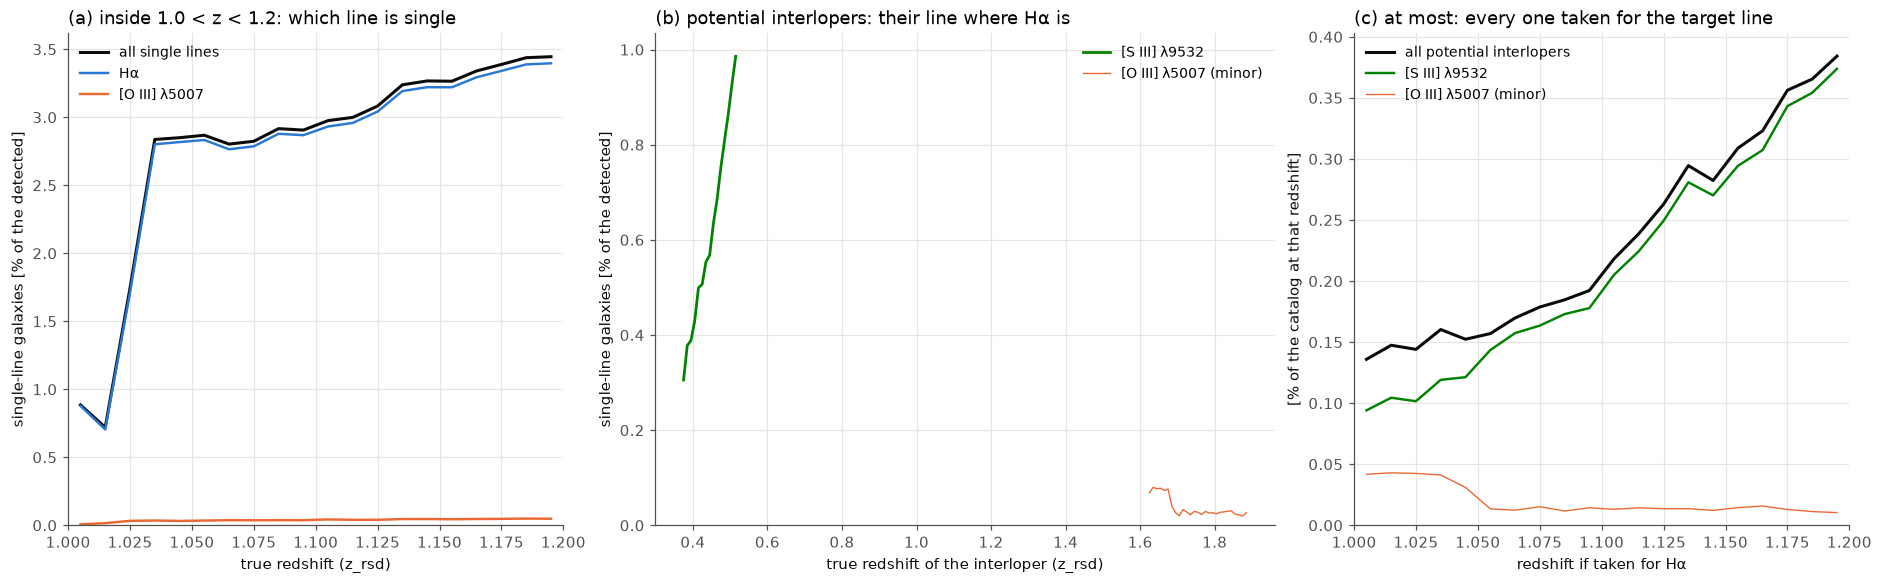

In [2]:
proposal = base.make_proposal((1.0, 1.2), line="Ha", flux_limit=1.5e-16, secondary_flux_limit=6e-17, rescaling=RESCALING,
                              n_workers=N_WORKERS)
proposal.plot()
plt.show()


What the proposal shows (flux limits 1.5 / 0.6 × 10⁻¹⁶):

* **The Hα sample**: 13.59 M galaxies with Hα detected at 1.0 ≤ z < 1.2, 5,273 per deg².
* **(a) 2.76 % of the detected galaxies inside the range are single-line, nearly all of them Hα** (2.72 %; their
  [O III] is below 0.6). [O III] is the single line in 5,106 galaxies (0.04 % of the detected galaxies, 1.4 % of the
  single-line ones): they are not in the Hα catalog, but they matter for the catalog of every galaxy below. The
  fraction rises from 2.8 % at z = 1.03 to 3.4 % at z = 1.2. Below z = 1.025 it is 0.7–0.9 %, because [S III] λ9532 is
  still in the bandpass and confirms Hα.
* **(b) One potential interloper**: [S III] λ9532 at 0.38 < z < 0.52 (28,226 single-line galaxies, 11 per deg²).
  [O III] λ5007 at 1.62 < z < 1.88 is minor (2,782, the thin line), and no other line is a potential interloper.
* **(c) At most** 0.14–0.38 % of the catalog against redshift, nearly all [S III], if every one of them were taken for
  Hα; 0.23 % in all, the "total" of the scan at the proposal's secondary limit of 6 × 10⁻¹⁷ (the column marked ⁴).
  The worst case, every single line an interloper and the single Hα lines lost, is 0.23 % as well.

### S/N thresholds instead of flux limits

The same with S/N ≥ 5 for one line and ≥ 2 for the others in the Roman grism: one hour, twice the minimum zodiacal light
(`exposure_time` and `background` change them). `size="r50_disk_2d"` gives each galaxy its own size, its disk
half-light radius; a number gives every galaxy that size in arcsec. The flux limits then depend on the observed
wavelength and on the size.

[romanmock] line = "Ha": which galaxies the catalog holds
  ▶ "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
    "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 32 of 67 slices with 64 worker(s) …

 done in 40 s



━━ Proposal · Hα at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    S/N ≥ 5 (other lines S/N ≥ 2), size r50_disk_2d [kpc] / D_A(redshift_true), 1 h, 2 x
                min zodi
  line fluxes   rescaled (line_factors)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 33 % of the detected
                galaxies with both lines in the bandpass
  sample        16,495,849 galaxies with Hα detected at 1.0 ≤ z < 1.2 (6,398 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line   galaxies  of all¹  of single¹
  ────  ─────────  ───────  ──────────
  all   3,412,105  20.68 %
  Ha    3,412,093  20.68 %    100.00 %
  ¹ of the 16,495,861 galaxies detected at 1.0 ≤ z < 1.2 (true redshift), and of the 3,412,105
    single-line ones among them
  minor (fewer than 100 

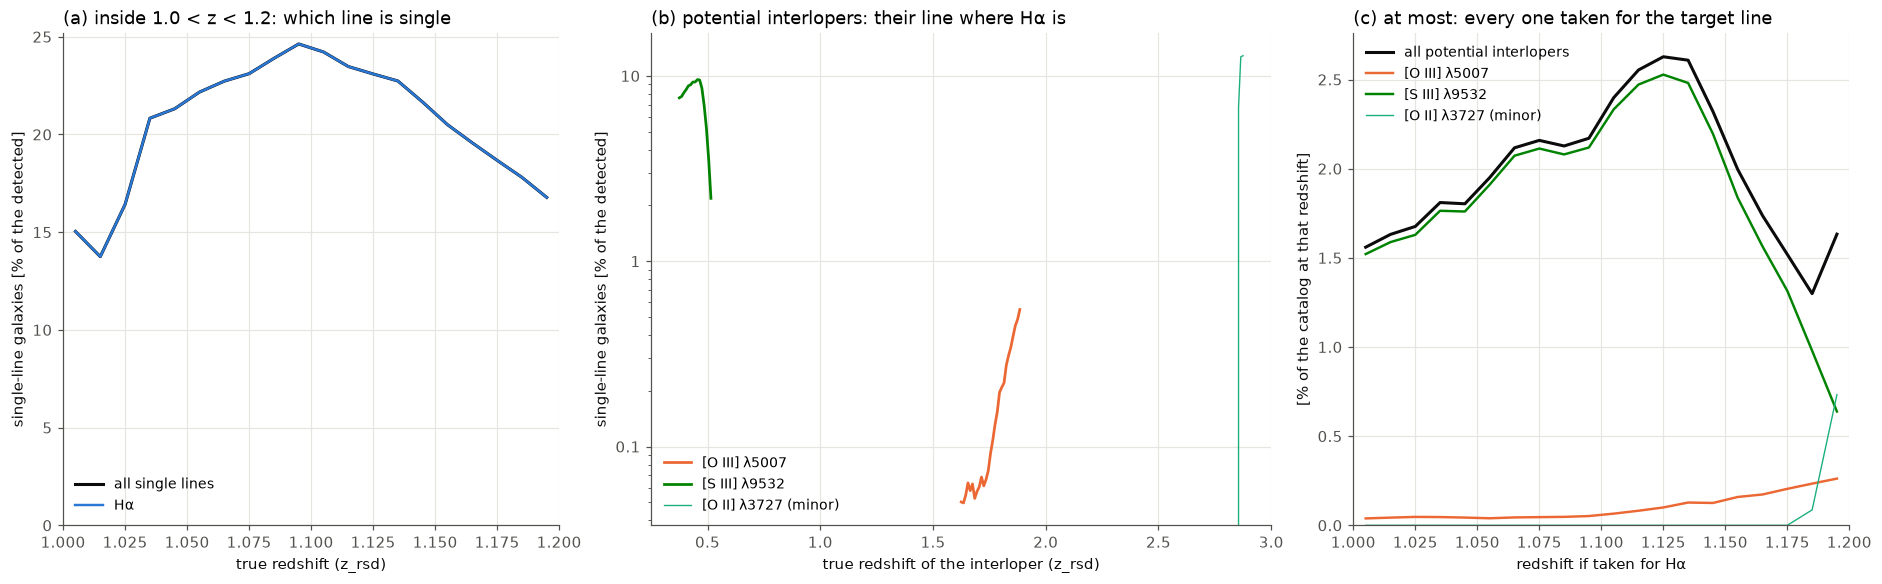

In [3]:
proposal_snr = base.make_proposal((1.0, 1.2), line="Ha", snr=5, secondary_snr=2, size="r50_disk_2d", rescaling=RESCALING,
                                  n_workers=N_WORKERS)
proposal_snr.plot()
plt.show()


With S/N ≥ 5 / 2 and the size of each galaxy:

* **The sample** is 16.50 M galaxies (6,398 per deg²). For compact galaxies the S/N limit is fainter than
  1.5 × 10⁻¹⁶.
* **(a) 20.7 % of the detected galaxies are single-line, 7.5 times the flux route, and all but 12 of them are Hα.** At
  1.0 < z < 1.2 [O III] falls at the blue edge of the grism (10 017–11 018 Å), where the noise is highest, and often
  misses S/N 2. The fraction peaks near 25 % at z = 1.1.
* **(b) Eleven times as many [S III] λ9532 potential interlopers**: 312,341 (121 per deg²). [O III], minor with the
  flux limits, adds 16,508 (6.4 per deg²); [O II] is minor (6,597, the thin line).
* **(c)** At most 2.0 % of the catalog in all (1.86 % [S III], 0.10 % [O III]). The worst case is 2.5 %: it also
  loses the 3.41 M single Hα lines.

The faintest of these thresholds is 30 times the base limit. The rescaling and the merged doublet together brighten a
line by 11.9 times at most, so the base catalog holds every galaxy these thresholds can reach.

### Every galaxy: `line="all"`

`line="all"` proposes the catalog of every galaxy with a redshift inside the range, whichever line gave it. A potential
interloper is then a pair: a single line that, taken for another line, gets a redshift inside the range. The line it
is taken for must be one that single-line galaxies inside the range actually show: the single line of at least 100
galaxies and 0.1 % of the single-line galaxies there (`proposal.assignable`). In the figure the colour is the true
line and the line style the line it would be taken for.

[romanmock] line = "all": which galaxies the catalog holds
    "Ha"         the galaxies in which Hα is identified, with z = λ_obs / 6564.7 Å − 1 inside
                 z_range: Hα detected, alone or with other lines, or a single line taken for Hα (an
                 interloper)
    "OIII_5007"  the same for [O III] λ5007, z = λ_obs / 5008.3 Å − 1; a galaxy with both lines is
                 in both catalogs
  ▶ "all"        every galaxy with a redshift inside z_range, whichever line gave it
    or           "Hb", "OIII_4959", "OII_3727", "SIII_9532", "SIII_9069", "OIII_4363", "SIII_6312",
                 "PaA"


[romanmock] proposal: scanning 60 of 67 slices with 64 worker(s) …

 done in 33 s



━━ Proposal · every galaxy at 1.0 ≤ z ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds    F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes   rescaled (line_factors)
  doublet       OIII_4959 a line of its own where the doublet is resolved for the galaxy's size
                (dip ≥ 20 %), added to OIII_5007 where blended; merged in 59 % of the detected
                galaxies with both lines in the bandpass
  sample        13,599,636 detected galaxies at 1.0 ≤ z < 1.2 (5,275 per deg²)

── Single-line galaxies inside the range ───────────────────────────────────────────────────────────
  line       galaxies  of all¹  of single¹
  ─────────  ────────  ───────  ──────────
  all         375,059   2.76 %
  Ha          369,953   2.72 %     98.64 %
  OIII_5007     5,106   0.04 %      1.36 %
  ¹ of the 13,599,636 galaxies detected at 1.0 ≤ z < 1.2 (true redshift), and of the 375,059
    single-line ones among them

── Potential interlopers ─────────────────────

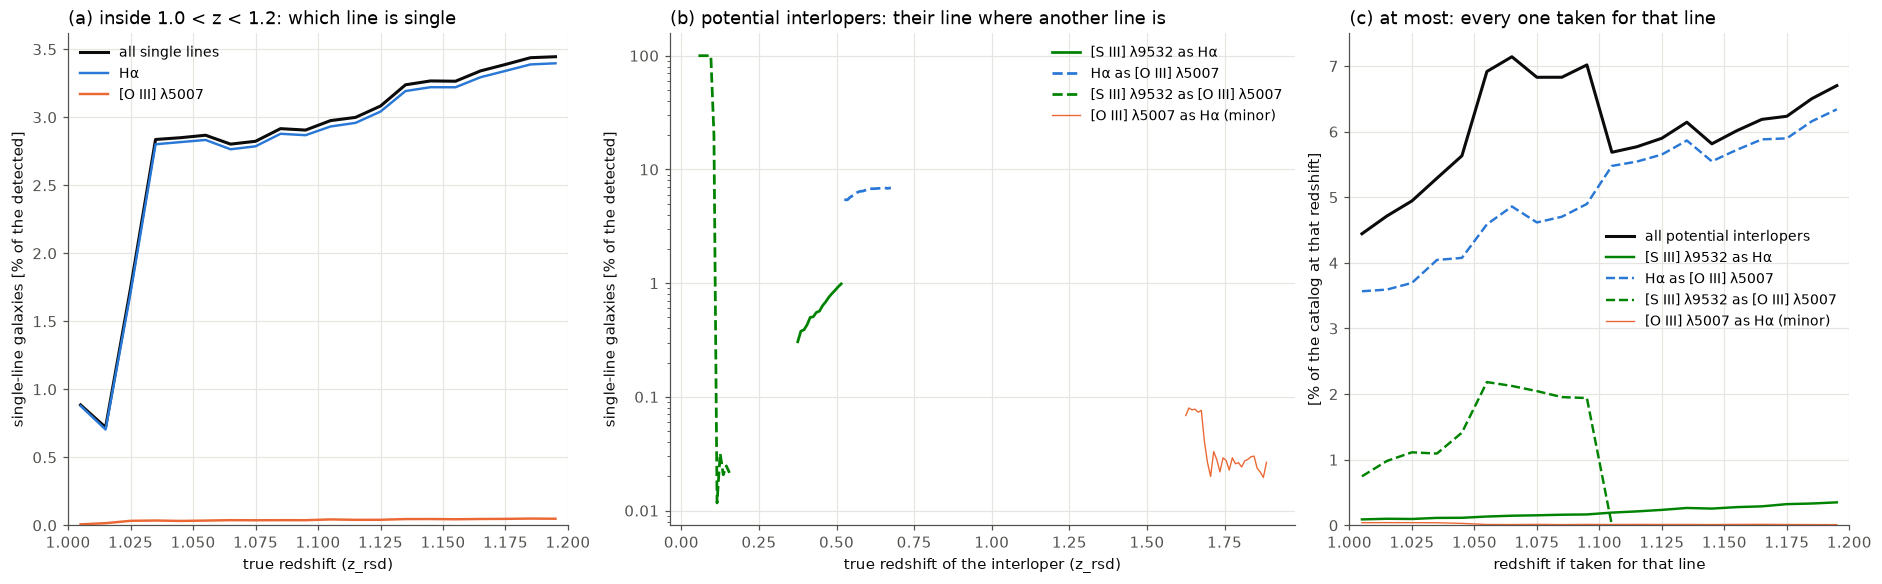

In [4]:
proposal_all = base.make_proposal((1.0, 1.2), line="all", flux_limit=1.5e-16, secondary_flux_limit=6e-17,
                                  rescaling=RESCALING, n_workers=N_WORKERS)
proposal_all.plot()
plt.show()


For every galaxy at 1.0 < z < 1.2 (flux limits 1.5 / 0.6):

* **The sample** is 13.60 M detected galaxies, 5,215 more than the Hα sample, nearly all of them (5,106) single
  [O III] lines.
* **The single-line galaxies inside the range are the same 2.76 %**: Hα in 98.6 % of them and [O III] in 1.4 %. A
  single line can be taken for either.
* **(b) Three potential pairs**:
  * Hα at 0.53–0.68 taken for [O III]: 721,584 (280 per deg², 6.5 % of the detected galaxies there), at most 5.0 % of
    the catalog. At 10 000–11 000 Å a single line is Hα at z ≈ 0.6 far more often than [O III] inside the range, so a
    line that is rarely single here opens the way to many interlopers;
  * [S III] λ9532 at 0.05–0.16 taken for [O III]: 119,718 (46 per deg²), at most 0.83 %, the only line of these
    galaxies in the bandpass;
  * [S III] λ9532 at 0.38–0.52 taken for Hα, the pair of the Hα catalog: 28,226 (11 per deg²), at most 0.20 %.
    [O III] taken for Hα is minor (2,782, the thin line).
* **(c) At most 6.0 % of the catalog in all**, 26 times the 0.23 % of the Hα catalog. The worst case, which also loses
  the single lines of the range, is 6.19 % (notebook 06 makes it).

The lines a single line can be taken for are chosen by their share of the *single-line* galaxies. As a share of every
detected galaxy, [O III] would be 0.04 %, below the cut, and these pairs would be left out.

## Step 2: the identification and the catalog

`proposal.confusion_template()` lists the rows a confusion table needs. For each potential interloper that is not
minor, it gives the probability that its single line is taken for Hα, which brings the galaxy into the catalog
(`p_interloper`). For Hα, it gives the probability that a single Hα line is taken for that line, which takes the galaxy
out (`p_target`). Lines not listed are identified correctly, and `{}` gives the clean catalog. The values below are an
assumed scenario, not a Roman calibration: 5 % and 0.5 %.

`make_catalog` writes to the directory:

* the catalog, `<name>.hdf5`;
* its summary, `<name>_summary.json`;
* the proposal, `<name>_proposal.npz`.

It prints the summary of the catalog (thresholds, identification, the galaxies per outcome) and the line report: the
lines inside the bandpass for the range, and the interlopers the identification let in.
`proposal_snr.make_catalog(...)` would make the S/N catalog the same way.

In [5]:
rows = proposal.confusion_template(p_interloper=0.05, p_target=0.005)     # an assumed scenario, not a Roman calibration
print(json.dumps(rows, indent=1))
cat = proposal.make_catalog(rows, OUT / "Ha_z1p0_1p2_matrix", n_workers=N_WORKERS)


{
 "Ha": {
  "SIII_9532": 0.005
 },
 "SIII_9532": {
  "Ha": 0.05
 }
}
[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 29 s



━━ Catalog · Hα · 1.0 ≤ z_assigned ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (line_factors); [O III] doublet per_galaxy
  identification   confusion matrix: Ha → SIII_9532 0.005, SIII_9532 → Ha 0.05
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     91,617,494 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 13,224,468   97.28 %
  single line, correct redshift                 368,006    2.71 %
  single line taken for another: interloper       1,356    0.01 %
  all                                        13,593,830  100.00 %

──


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_matrix/
            Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_summary.json, Ha_z1p0_1p2_proposal.npz


### The line mix of the mock instead of a table

`"empirical"` gives each single-line galaxy a line drawn from the line mix of the single-line galaxies of the mock at
the same observed wavelength and flux rank. That is an identification from the observed wavelength and flux alone. The
table of the mix (`base.line_fractions`) is built first, at the same thresholds and with the same rescaling and doublet
rule, which costs one more pass.

In [6]:
cat_emp = proposal.make_catalog("empirical", OUT / "Ha_z1p0_1p2_empirical", n_workers=N_WORKERS)


[romanmock] line mix of the single-line galaxies: scanning 67 slices with 64 worker(s) …

 done in 31 s



── Line mix of the single-line galaxies (empirical identification) ─────────────────────────────────
  galaxies     5,126,254 single-line galaxies (F > 1.5e-16, other lines < 6e-17)
  bins         37 wavelength bins × 113–521 flux-rank bins (galaxies_per_bin 500)
  assignment   mode draw
  lines used   Ha, OIII_5007, OII_3727, SIII_9532, PaA

  λ_obs [Å]    galaxies  flux bins    Ha  OIII_5007  OII_3727  SIII_9532  PaA  brightest bin
  ───────────  ────────  ─────────  ────  ─────────  ────────  ─────────  ───  ───────────────
  10000–10251   184,546        369  78.1        0.5         ·       21.4    ·  SIII_9532 100 %
  10251–10503   260,692        521  69.1        0.5         ·       30.4    ·  SIII_9532 100 %
  10503–10754   201,661        403  98.0        0.7         ·        1.3    ·  SIII_9532 100 %
  10754–11005   199,297        398  99.2        0.7         ·        0.0    ·  OIII_5007 62 %
  11005–11257   210,310        420  99.3        0.7         ·        0.0    ·  OIII_500

[romanmock] catalog: scanning 67 slices with 64 worker(s) …

 done in 30 s



━━ Catalog · Hα · 1.0 ≤ z_assigned ≤ 1.2 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  thresholds       F > 1.50e-16 (other lines > 6.00e-17)
  line fluxes      rescaled (line_factors); [O III] doublet per_galaxy
  identification   the line mix of the mock (empirical)
  sky area         2578.31 deg² (estimated from the sky patches of the mock)
  base catalog     91,617,494 of its 403,068,868 galaxies detected
  columns          gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome,
                   line_true, line_assigned, n_det

  galaxies                                       number     share
  ─────────────────────────────────────────  ──────────  ────────
  multi-line                                 13,224,468   97.27 %
  single line, correct redshift                 347,045    2.55 %
  single line taken for another: interloper      24,269    0.18 %
  all                                        13,595,782  100.00 %

── Lines in the bandpass,


[romanmock] wrote to /pscratch/sd/w/willlake/RomanMocks/examples/Ha_z1p0_1p2_empirical/
            Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_summary.json, Ha_z1p0_1p2_proposal.npz


## What is in the catalog

`id_outcome` tells the galaxies apart:

* 1: a multi-line galaxy;
* 2: a single-line galaxy with a correct redshift;
* 3: a single line taken for another line, an interloper with a wrong redshift. `line_true` and `line_assigned` give
  the two lines, as indices into `cat.line_names`.

`cat.components()` counts each component, with one entry per kind of interloper, e.g. `"OIII_5007_as_Ha"`, and
`cat.subset(which)` returns one of them. Notebook 03 makes randoms for these components.

(a) assumed confusion table: 13,593,830 galaxies
  all                       13,593,830   100.000 %


  multi_line                13,224,468    97.283 %


  single_correct               368,006     2.707 %
  galaxies                  13,592,474    99.990 %
  interlopers                    1,356     0.010 %
  SIII_9532_as_Ha                1,356     0.010 %


(b) line mix of the mock: 13,595,782 galaxies
  all                       13,595,782   100.000 %


  multi_line                13,224,468    97.269 %


  single_correct               347,045     2.553 %


  galaxies                  13,571,513    99.821 %
  interlopers                   24,269     0.179 %
  SIII_9532_as_Ha               21,753     0.160 %
  OIII_5007_as_Ha                2,516     0.019 %


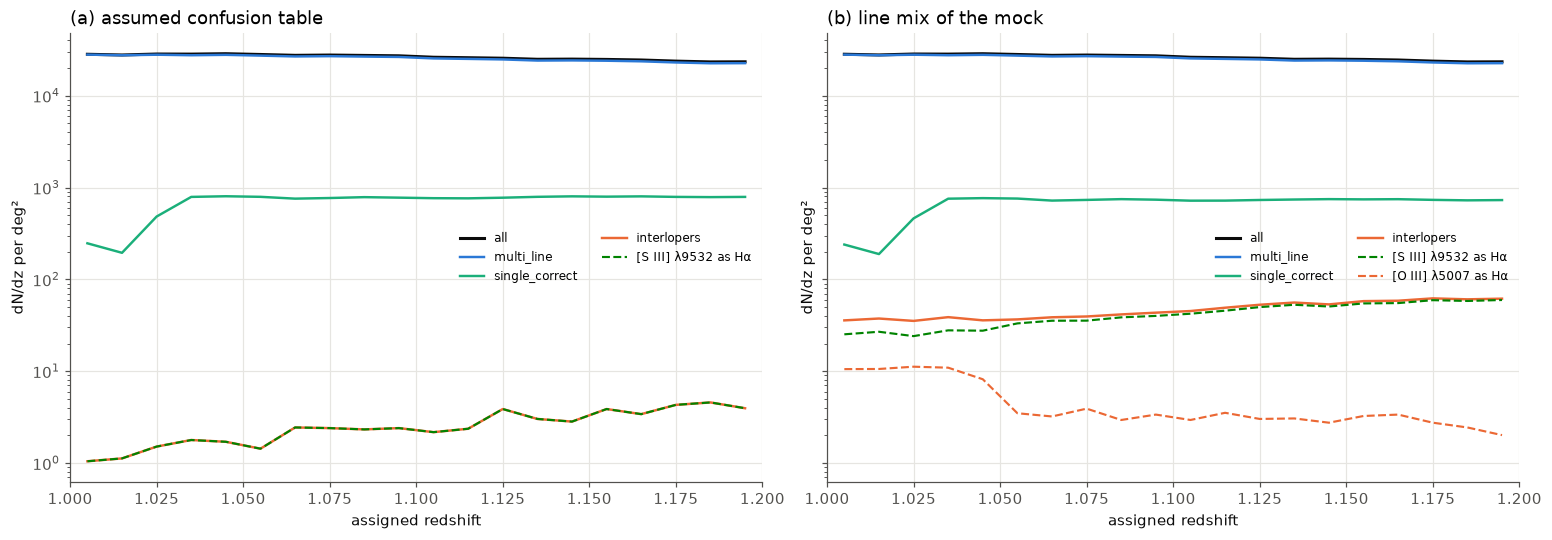

In [7]:
COLORS = {"all": TEXT_PRIMARY, "multi_line": OUTCOME_COLORS["MULTI_LINE"], "single_correct": OUTCOME_COLORS["SINGLE_CORRECT"],
          "interlopers": OUTCOME_COLORS["SINGLE_MISID"]}


def show_components(cat, name, ax, edges, min_count=100):
    """Print the components of a catalog and draw dN/dz of each against the assigned redshift. A kind of interloper
    has the colour of its true line and one line style per line it is taken for; those with fewer than min_count
    galaxies are listed only."""
    comp = cat.components()
    zc = 0.5 * (edges[1:] + edges[:-1])
    styles = {}
    print(f"{name}: {len(cat):,} galaxies")
    for which, n in comp.items():
        print(f"  {which:<24s}{n:>12,}{100 * n / comp['all']:>10.3f} %")
        if which == "galaxies" or n < min_count:
            continue
        if which in COLORS:
            ax.plot(zc, cat.subset(which).dndz(edges), color=COLORS[which], lw=2.0 if which == "all" else 1.6, label=which)
        else:
            true, taken = which.split("_as_")
            ls = styles.setdefault(taken, ("--", ":", "-.")[len(styles) % 3])
            ax.plot(zc, cat.subset(which).dndz(edges), color=feature_color(true), ls=ls, lw=1.4,
                    label=f"{feature_label(true)} as {feature_label(taken)}")
    ax.set_yscale("log")
    ax.set_xlim(edges[0], edges[-1])
    ax.set_xlabel("assigned redshift")
    ax.set_ylabel("dN/dz per deg²")
    ax.set_title(name, loc="left")
    ax.legend(fontsize=8, ncol=2)


edges = np.linspace(1.0, 1.2, 21)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True, sharey=True)
show_components(cat, "(a) assumed confusion table", axes[0], edges)
show_components(cat_emp, "(b) line mix of the mock", axes[1], edges)
plt.show()


The two catalogs share their 13.22 M multi-line galaxies (97.3 %) and differ in the single-line ones:

* **(a) The assumed table** takes 5 % of the potential interlopers for Hα: 1,356 interlopers (0.01 %), all [S III]
  λ9532. It loses 0.5 % of the single Hα lines, taken for [S III] λ9532.
* **(b) The line mix of the mock** gives 24,269 interlopers (0.18 %), 21,753 [S III] λ9532 and 2,516 [O III]. At
  13 000–14 500 Å the single lines of the mock are 90–97 % Hα, so a drawn identification takes most of the others for
  Hα: 77 % of the [S III] λ9532 potential interlopers and 90 % of the [O III] ones. It takes 6 % of the single Hα
  lines for another line.

The single-line galaxies with a correct redshift drop below z = 1.025, where [S III] λ9532 confirms Hα. The interlopers
lie about 4.0 (table) and 2.7 (mix) orders of magnitude below the multi-line galaxies, across the whole range.

## The files

`Catalog.read` reads a catalog back. The summary holds the settings, the outcome counts, the line report and the numbers
of the proposal. `Proposal.load` reopens a proposal, so step 2 can be redone later with another identification.

In [8]:
for d in ("Ha_z1p0_1p2_matrix", "Ha_z1p0_1p2_empirical"):
    print(d + ":", ", ".join(sorted(p.name for p in (OUT / d).iterdir() if p.is_file())))
back = Catalog.read(OUT / "Ha_z1p0_1p2_matrix" / "Ha_z1p0_1p2.hdf5")
again = Proposal.load(OUT / "Ha_z1p0_1p2_matrix" / "Ha_z1p0_1p2_proposal.npz")
summary = json.loads((OUT / "Ha_z1p0_1p2_matrix" / "Ha_z1p0_1p2_summary.json").read_text())
print(f"read back: {len(back):,} galaxies; columns {', '.join(back.columns)}")
print(again)
print("summary:", ", ".join(summary))
wrong = back["id_outcome"] == 3
names = np.array(back.line_names)
print("first interlopers:", [f"{t} as {a}" for t, a in zip(names[back["line_true"][wrong][:3]], names[back["line_assigned"][wrong][:3]])])


Ha_z1p0_1p2_matrix: Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_proposal.npz, Ha_z1p0_1p2_summary.json
Ha_z1p0_1p2_empirical: Ha_z1p0_1p2.hdf5, Ha_z1p0_1p2_proposal.npz, Ha_z1p0_1p2_summary.json
read back: 13,593,830 galaxies; columns gal_id, ra, dec, redshift_true, redshift_rsd, redshift_assigned, id_outcome, line_true, line_assigned, n_det
<Proposal: Ha at 1.0–1.2, 13,594,421 galaxies; potential interlopers: SIII_9532>
summary: catalog, n_galaxies, outcomes, settings, line_report, area_deg2, proposal, written
first interlopers: ['SIII_9532 as Ha', 'SIII_9532 as Ha', 'SIII_9532 as Ha']


## Summary

* **Step 1, `make_proposal`**, gives the single-line galaxies of the catalog and its potential interlopers before any
  identification is chosen. For Hα at 1.0–1.2, with the oxygen lines rescaled:
  * flux limits 1.5 / 0.6: 2.76 % single-line, nearly all Hα, and one potential interloper, [S III] λ9532, at most
    0.23 % of the catalog with the minor [O III];
  * S/N 5 / 2: 20.7 % single-line, and eleven times as many potential interlopers, at most 2.0 %;
  * every galaxy (`line="all"`): single lines can also be taken for [O III], the single line of 1.4 % of the
    single-line galaxies, and Hα at z ≈ 0.6 taken for it brings the most to 6.0 % (6.19 % in the worst case,
    notebook 06).
* **Step 2, `proposal.make_catalog(confusion, out_dir)`**, writes the catalog with the chosen identification: 1,356
  interlopers (0.01 %) with the assumed table, 24,269 (0.18 %) with the line mix of the mock.
* **`cat.components()` and `cat.subset(which)`** split a catalog into multi-line galaxies, single-line galaxies with a
  correct redshift, and each kind of interloper. Notebook 03 makes their randoms; notebook 04 builds catalogs by
  their interloper fractions, notebook 05 single-line clean catalogs, and notebook 06 the worst case.
* The notebook ran in 2.9 minutes on a CPU node.